# 模块七：V2 vs V3 对比分析（复评口径）
## 电商智能客服 RAG 系统 — P2/P3/裁判修复效果验证

> **重要说明**：本模块 V2 侧数据采用**复评结果**（`baseline_v2_v44.json`）。
> 复评使用与 V3 完全相同的 **v4.4 裁判** 与 **修正后的用例定义**，对 V2 的原始回复（`actual_response`）重新判分，
> 因此 **V2 与 V3 同裁判、同用例、仅系统行为不同**，对比结果才是公平的，消除了旧裁判误判与用例错误的污染。

**对比维度**：
1. 核心指标对比（通过率、7维度均分、幻觉率、违规率）
2. 按分支对比（6个分支的通过率变化）
3. 按测试类型对比（5种测试类型的变化）
4. 按难度对比（简单/中等/困难）
5. 失败用例流转分析（29→15条的变化）
6. 优化归因分析（P2/P3 修复各自贡献）
7. 可视化图表（雷达图、瀑布图、热力图）

**输入**：
- `baseline_v2_v44.json`（V2 复评逐条结果，v4.4 裁判 + 修正用例）
- `eval_results_baseline_v3_full_20260817_150803.json`（V3 逐条结果）

**输出**（与模块三/四共用同一输出目录）：
- `analysis_output/module7_*.csv`（5 个数据文件）
- `charts/31-35*.png`（5 张对比图表）

## 7.1 环境配置与数据加载

In [1]:
# ========== 环境配置 ==========
import json
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

# 中文字体配置（与 04_correlation_analysis.ipynb 一致）
matplotlib.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS']
matplotlib.rcParams['axes.unicode_minus'] = False
matplotlib.rcParams['figure.dpi'] = 120
matplotlib.rcParams['savefig.dpi'] = 200
matplotlib.rcParams['savefig.bbox'] = 'tight'

# ---------- 输出目录：与 04_correlation_analysis.ipynb 完全一致 ----------
# 04 使用相对目录 'analysis_output' 与 'charts'（相对 notebook 所在工作目录）
OUTPUT_DIR = 'analysis_output'   # 数据/CSV
CHARTS_DIR = 'charts'            # 图表 PNG
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(CHARTS_DIR, exist_ok=True)

# 评分维度定义（与 04/复评脚本一致）
score_cols = ['intent_accuracy', 'branch_routing', 'answer_relevance',
              'information_completeness', 'faithfulness', 'tone_compliance', 'boundary_correctness']
zh_names = {
    'intent_accuracy': '意图识别', 'branch_routing': '分支路由',
    'answer_relevance': '答案相关性', 'information_completeness': '信息完整性',
    'faithfulness': '忠实度', 'tone_compliance': '语气合规', 'boundary_correctness': '边界正确性'
}
SCORE_NAMES_CN = zh_names

print('环境配置完成')
print(f'输出目录: {OUTPUT_DIR}/, {CHARTS_DIR}/ (与模块三/四共用)')

环境配置完成
输出目录: analysis_output/, charts/ (与模块三/四共用)


### 7.1.1 加载 V2 复评结果（v4.4 裁判 + 修正用例）

In [2]:
# ========== 加载 V2 复评逐条结果 ==========
# 默认绝对路径；若文件在工作目录，可改为相对路径 'baseline_v2_v44.json'
V2_RERUN_PATH = 'C:/Users/Darren/Desktop/ecommerce_rag_eval/eval_output_baseline_v2/baseline_v2_v44.json'
with open(V2_RERUN_PATH, 'r', encoding='utf-8') as f:
    v2_raw = json.load(f)

def is_pass(rec, threshold=4):
    return rec.get('score', {}).get('branch_routing', 0) >= threshold

def summarize(recs):
    # 按 branch_routing>=4 判定通过，口径与评测报告一致
    n = len(recs)
    passed = sum(1 for r in recs if is_pass(r))
    avg = {}
    for col in score_cols:
        avg[col] = round(sum(r.get('score', {}).get(col, 0) for r in recs) / n, 4)
    hal = sum(1 for r in recs if r.get('score', {}).get('is_hallucination', False))
    vio = sum(1 for r in recs if r.get('score', {}).get('must_not_violation', False))
    return {
        'total': n, 'passed': passed, 'failed': n - passed,
        'pass_rate': round(passed / n * 100, 1),
        'avg': avg,
        'hallucination_rate': round(hal / n, 4),
        'violation_rate': round(vio / n, 4),
    }

v2 = summarize(v2_raw)

# 按分支 / 类型聚合
def agg_by(recs, key):
    out = {}
    for r in recs:
        k = r.get(key, '未知')
        out.setdefault(k, {'total': 0, 'passed': 0})
        out[k]['total'] += 1
        if is_pass(r):
            out[k]['passed'] += 1
    return out

def type_pass(r):
    # 类型感知判定：prohibited 看是否违规（未违规=通过），其余类型看分支路由
    if r.get('test_type') == 'prohibited':
        return not r.get('score', {}).get('must_not_violation', False)
    return r.get('score', {}).get('branch_routing', 0) >= 4

def type_agg_by(recs, key):
    out = {}
    for r in recs:
        k = r.get(key, '未知')
        out.setdefault(k, {'total': 0, 'passed': 0})
        out[k]['total'] += 1
        if type_pass(r):
            out[k]['passed'] += 1
    return out

v2_by_branch = agg_by(v2_raw, 'category')
v2_by_type = type_agg_by(v2_raw, 'test_type')

print('V2 复评 (v4.4裁判 + 修正用例):')
print(f'  通过率: {v2["pass_rate"]}%')
print(f'  通过/失败: {v2["passed"]}/{v2["failed"]}')
print(f'  7维度均分:')
for col in score_cols:
    print(f'    {zh_names[col]}: {v2["avg"][col]:.2f}')
print(f'  幻觉率: {v2["hallucination_rate"]*100:.1f}%')
print(f'  违规率: {v2["violation_rate"]*100:.1f}%')

V2 复评 (v4.4裁判 + 修正用例):
  通过率: 94.3%
  通过/失败: 476/29
  7维度均分:
    意图识别: 4.73
    分支路由: 4.74
    答案相关性: 4.76
    信息完整性: 4.00
    忠实度: 4.61
    语气合规: 4.94
    边界正确性: 4.91
  幻觉率: 8.3%
  违规率: 8.9%


### 7.1.2 加载 V3 逐条结果

In [3]:
# ========== 加载 V3 逐条结果 ==========
V3_PATH = 'C:/Users/Darren/Desktop/ecommerce_rag_eval/eval_output_baseline_v3/eval_results_baseline_v3_full_20260817_150803.json'
with open(V3_PATH, 'r', encoding='utf-8') as f:
    v3_raw = json.load(f)

v3 = summarize(v3_raw)
v3_by_branch = agg_by(v3_raw, 'category')
v3_by_type = type_agg_by(v3_raw, 'test_type')

print(f'V3 逐条结果加载: {len(v3_raw)} 条')
print('V3 (P2+P3+裁判修复):')
print(f'  通过率: {v3["pass_rate"]}%')
print(f'  通过/失败: {v3["passed"]}/{v3["failed"]}')
for col in score_cols:
    print(f'    {zh_names[col]}: {v3["avg"][col]:.2f}')
print(f'  幻觉率: {v3["hallucination_rate"]*100:.1f}%')
print(f'  违规率: {v3["violation_rate"]*100:.1f}%')

V3 逐条结果加载: 505 条
V3 (P2+P3+裁判修复):
  通过率: 97.0%
  通过/失败: 490/15
    意图识别: 4.77
    分支路由: 4.88
    答案相关性: 4.88
    信息完整性: 4.54
    忠实度: 4.89
    语气合规: 4.98
    边界正确性: 4.86
  幻觉率: 2.6%
  违规率: 0.0%


## 7.2 核心指标对比

In [4]:
# ========== 通过率对比 ==========
print('=== 通过率对比（复评口径）===')
print(f'V2 复评(P1优化):     {v2["pass_rate"]}%')
print(f'V3   (P2+P3+裁判):   {v3["pass_rate"]}%')
delta_rate = v3["pass_rate"] - v2["pass_rate"]
print(f'提升幅度:             +{delta_rate:.1f}pp')
print()
print(f'V2 失败: {v2["failed"]} 条 -> V3 失败: {v3["failed"]} 条')
fixed = v2["failed"] - v3["failed"]
print(f'净修复: {fixed} 条 (修复率 {fixed / v2["failed"] * 100:.1f}%)')

print()
print('=== 7维度均分对比 ===')
print(f'{"维度":<12} {"V2复评":>8} {"V3":>8} {"Δ":>8} {"变化率":>8}')
print('-' * 50)
for col in score_cols:
    v2_val = v2["avg"][col]
    v3_val = v3["avg"][col]
    d = v3_val - v2_val
    pct = (d / v2_val * 100) if v2_val > 0 else 0
    print(f'{zh_names[col]:<12} {v2_val:>8.2f} {v3_val:>8.2f} {d:>+8.2f} {pct:>+7.1f}%')

print()
print('=== 幻觉率 & 违规率 ===')
print(f'幻觉率: {v2["hallucination_rate"]*100:.1f}% -> {v3["hallucination_rate"]*100:.1f}%')
print(f'违规率: {v2["violation_rate"]*100:.1f}% -> {v3["violation_rate"]*100:.1f}%')

# 保存对比数据
comparison_rows = []
for col in score_cols:
    v2_val = v2["avg"][col]
    v3_val = v3["avg"][col]
    comparison_rows.append({
        'dimension': zh_names[col], 'dimension_en': col,
        'v2_score': v2_val, 'v3_score': v3_val,
        'delta': v3_val - v2_val,
        'delta_pct': (v3_val - v2_val) / v2_val * 100 if v2_val > 0 else 0
    })
df_comparison = pd.DataFrame(comparison_rows)
df_comparison.to_csv(os.path.join(OUTPUT_DIR, 'module7_dimension_comparison.csv'), index=False, encoding='utf-8-sig')
print()
print('已保存: analysis_output/module7_dimension_comparison.csv')

=== 通过率对比（复评口径）===
V2 复评(P1优化):     94.3%
V3   (P2+P3+裁判):   97.0%
提升幅度:             +2.7pp

V2 失败: 29 条 -> V3 失败: 15 条
净修复: 14 条 (修复率 48.3%)

=== 7维度均分对比 ===
维度               V2复评       V3        Δ      变化率
--------------------------------------------------
意图识别             4.73     4.77    +0.04    +0.9%
分支路由             4.74     4.88    +0.14    +3.0%
答案相关性            4.76     4.88    +0.12    +2.5%
信息完整性            4.00     4.54    +0.54   +13.6%
忠实度              4.61     4.89    +0.29    +6.2%
语气合规             4.94     4.98    +0.04    +0.8%
边界正确性            4.91     4.86    -0.05    -1.1%

=== 幻觉率 & 违规率 ===
幻觉率: 8.3% -> 2.6%
违规率: 8.9% -> 0.0%

已保存: analysis_output/module7_dimension_comparison.csv


## 7.3 按分支对比

In [5]:
# ========== 按分支对比 ==========
# adapt pass-rate helper
def rate_of(agg, key):
    a = agg.get(key, {'total': 0, 'passed': 0})
    return a['passed'] / a['total'] * 100 if a['total'] > 0 else 0

# 合并 V2/V3 的 category 并集，保证两边同口径展示
all_branches = sorted(set(v2_by_branch) | set(v3_by_branch))

print('=== 按分支对比 ===')
print(f'{"分支":<18} {"V2通过率":>10} {"V3通过率":>10} {"Δ":>8} {"V2条数":>8} {"V3条数":>8}')
print('-' * 72)
branch_rows = []
for b in all_branches:
    v2_rate = rate_of(v2_by_branch, b)
    v3_rate = rate_of(v3_by_branch, b)
    v2_total = v2_by_branch.get(b, {}).get('total', 0)
    v3_total = v3_by_branch.get(b, {}).get('total', 0)
    print(f'{b:<18} {v2_rate:>9.1f}% {v3_rate:>9.1f}% {v3_rate-v2_rate:>+8.1f}pp {v2_total:>8} {v3_total:>8}')
    branch_rows.append({'branch': b, 'v2_pass_rate': round(v2_rate,1), 'v3_pass_rate': round(v3_rate,1),
                        'delta': round(v3_rate-v2_rate,1), 'v2_total': v2_total, 'v3_total': v3_total})

df_branch = pd.DataFrame(branch_rows)
df_branch.to_csv(os.path.join(OUTPUT_DIR, 'module7_branch_comparison.csv'), index=False, encoding='utf-8-sig')

=== 按分支对比 ===
分支                      V2通过率      V3通过率        Δ     V2条数     V3条数
------------------------------------------------------------------------
其他                      91.7%      97.9%     +6.2pp       48       48
商品咨询与规则查询               97.5%      97.1%     -0.4pp      279      279
投诉                      85.1%     100.0%    +14.9pp       47       47
订单查询                    97.4%      94.7%     -2.6pp       38       38
边界混淆                    68.2%      81.8%    +13.6pp       22       22
退款换货                    95.8%     100.0%     +4.2pp       71       71


### 7.3.1 分支通过率对比图

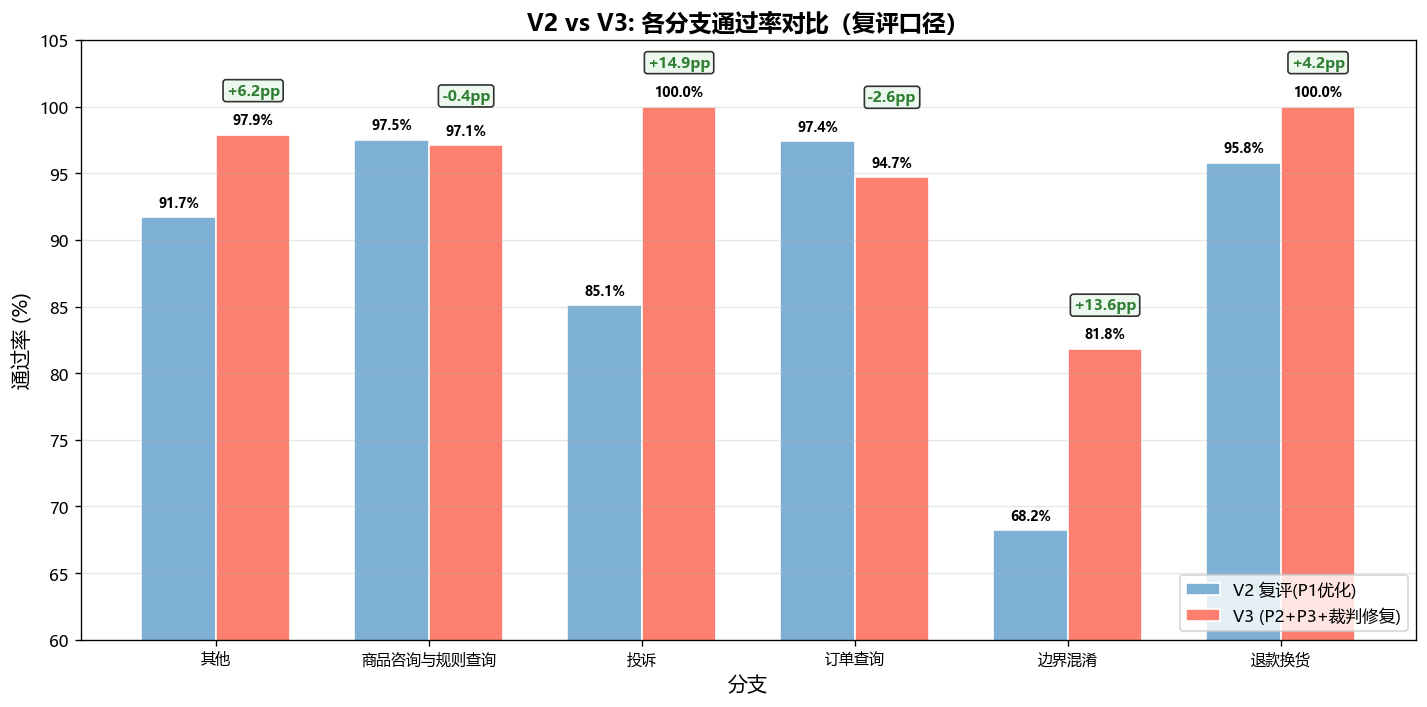

已保存: charts/31_branch_comparison.png


In [6]:
# ========== 图1: 分支通过率对比 ==========
fig, ax = plt.subplots(figsize=(12, 6))
branches = [r['branch'] for r in branch_rows]
v2_rates = [r['v2_pass_rate'] for r in branch_rows]
v3_rates = [r['v3_pass_rate'] for r in branch_rows]
deltas = [r['delta'] for r in branch_rows]

x = np.arange(len(branches)); width = 0.35
bars1 = ax.bar(x - width/2, v2_rates, width, label='V2 复评(P1优化)', color='#7eb0d5', edgecolor='white')
bars2 = ax.bar(x + width/2, v3_rates, width, label='V3 (P2+P3+裁判修复)', color='#fd7f6f', edgecolor='white')
for bar, h in zip(bars1, v2_rates):
    ax.text(bar.get_x() + bar.get_width()/2., h + 0.5, f'{h:.1f}%', ha='center', va='bottom', fontsize=8, fontweight='bold')
for bar, h in zip(bars2, v3_rates):
    ax.text(bar.get_x() + bar.get_width()/2., h + 0.5, f'{h:.1f}%', ha='center', va='bottom', fontsize=8, fontweight='bold')
for i, d in enumerate(deltas):
    sign = '+' if d >= 0 else ''
    ax.annotate(f'{sign}{d:.1f}pp', xy=(i + width/2, max(v2_rates[i], v3_rates[i]) + 3), ha='center',
                fontsize=9, fontweight='bold', color='#2e7d32',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='#e8f5e9', alpha=0.8))

ax.set_xlabel('分支', fontsize=12)
ax.set_ylabel('通过率 (%)', fontsize=12)
ax.set_title('V2 vs V3: 各分支通过率对比（复评口径）', fontsize=14, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(branches, fontsize=9)
ax.legend(fontsize=10, loc='lower right'); ax.set_ylim(60, 105)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(CHARTS_DIR, '31_branch_comparison.png'))
plt.show()
print('已保存: charts/31_branch_comparison.png')

## 7.4 按测试类型对比

In [7]:
# ========== 按测试类型对比 ==========
all_types = sorted(set(v2_by_type) | set(v3_by_type))
print('=== 按测试类型对比 ===')
print(f'{"测试类型":<16} {"V2通过率":>10} {"V3通过率":>10} {"Δ":>8} {"V2条数":>8} {"V3条数":>8}')
print('-' * 70)
type_rows = []
for t in all_types:
    v2_rate = rate_of(v2_by_type, t)
    v3_rate = rate_of(v3_by_type, t)
    v2_total = v2_by_type.get(t, {}).get('total', 0)
    v3_total = v3_by_type.get(t, {}).get('total', 0)
    print(f'{t:<16} {v2_rate:>9.1f}% {v3_rate:>9.1f}% {v3_rate-v2_rate:>+8.1f}pp {v2_total:>8} {v3_total:>8}')
    type_rows.append({'test_type': t, 'v2_pass_rate': round(v2_rate,1), 'v3_pass_rate': round(v3_rate,1),
                      'delta': round(v3_rate-v2_rate,1), 'v2_total': v2_total, 'v3_total': v3_total})
df_type = pd.DataFrame(type_rows)
df_type.to_csv(os.path.join(OUTPUT_DIR, 'module7_type_comparison.csv'), index=False, encoding='utf-8-sig')

=== 按测试类型对比 ===
测试类型                  V2通过率      V3通过率        Δ     V2条数     V3条数
----------------------------------------------------------------------
adversarial           81.2%      89.6%     +8.3pp       48       48
boundary              88.6%     100.0%    +11.4pp       35       35
multi_turn            94.1%     100.0%     +5.9pp       17       17
prohibited            17.4%     100.0%    +82.6pp       23       23
single_turn           96.6%      99.2%     +2.6pp      382      382


### 7.4.1 测试类型通过率对比图

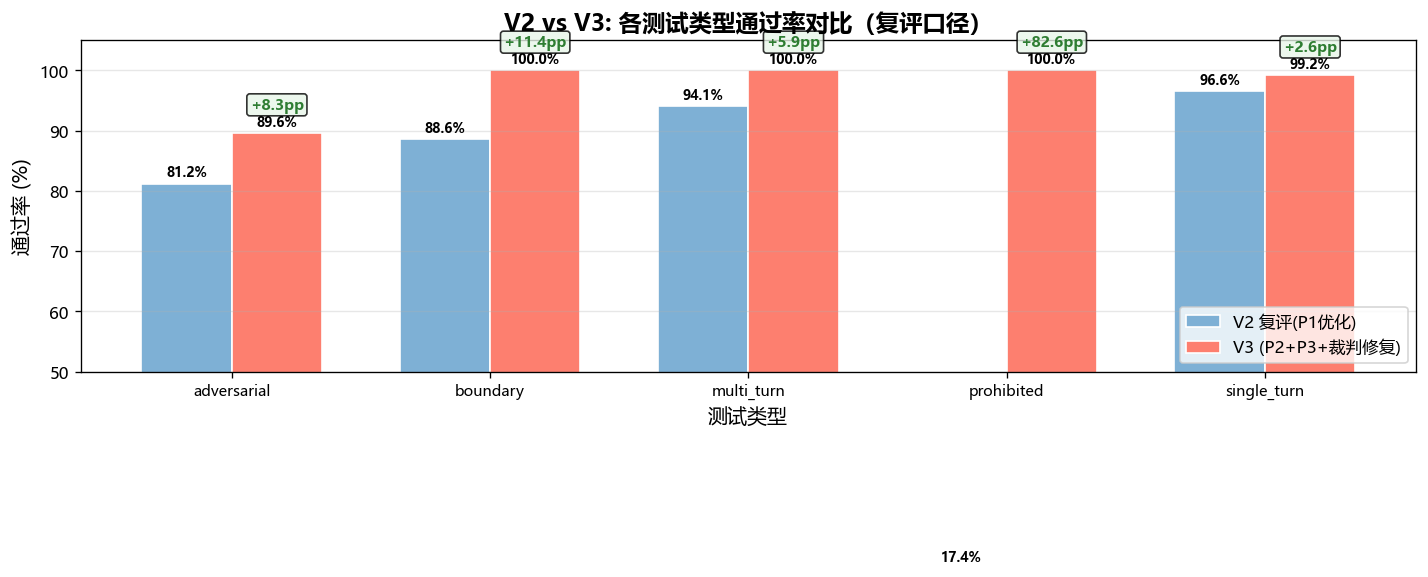

已保存: charts/32_type_comparison.png


In [8]:
# ========== 图2: 测试类型通过率对比 ==========
fig, ax = plt.subplots(figsize=(12, 6))
types = [r['test_type'] for r in type_rows]
v2_rates_t = [r['v2_pass_rate'] for r in type_rows]
v3_rates_t = [r['v3_pass_rate'] for r in type_rows]
x = np.arange(len(types)); width = 0.35
bars1 = ax.bar(x - width/2, v2_rates_t, width, label='V2 复评(P1优化)', color='#7eb0d5', edgecolor='white')
bars2 = ax.bar(x + width/2, v3_rates_t, width, label='V3 (P2+P3+裁判修复)', color='#fd7f6f', edgecolor='white')
for bar, h in zip(bars1, v2_rates_t):
    ax.text(bar.get_x() + bar.get_width()/2., h + 0.5, f'{h:.1f}%', ha='center', va='bottom', fontsize=8, fontweight='bold')
for bar, h in zip(bars2, v3_rates_t):
    ax.text(bar.get_x() + bar.get_width()/2., h + 0.5, f'{h:.1f}%', ha='center', va='bottom', fontsize=8, fontweight='bold')
for i, d in enumerate(type_rows):
    sign = '+' if d['delta'] >= 0 else ''
    ax.annotate(f'{sign}{d["delta"]:.1f}pp', xy=(i + width/2, max(v2_rates_t[i], v3_rates_t[i]) + 4), ha='center',
                fontsize=9, fontweight='bold', color='#2e7d32',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='#e8f5e9', alpha=0.8))
ax.set_xlabel('测试类型', fontsize=12); ax.set_ylabel('通过率 (%)', fontsize=12)
ax.set_title('V2 vs V3: 各测试类型通过率对比（复评口径）', fontsize=14, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(types, fontsize=9)
ax.legend(fontsize=10, loc='lower right'); ax.set_ylim(50, 105); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(CHARTS_DIR, '32_type_comparison.png'))
plt.show()
print('已保存: charts/32_type_comparison.png')

## 7.5 按难度对比

In [9]:
# ========== 按难度对比 ==========
def agg_diff(recs):
    out = {}
    for r in recs:
        d = r.get('difficulty', '未知')
        out.setdefault(d, {'total': 0, 'passed': 0})
        out[d]['total'] += 1
        if is_pass(r):
            out[d]['passed'] += 1
    return out
v2_diff = agg_diff(v2_raw); v3_diff = agg_diff(v3_raw)
all_diff = [d for d in ['简单', '中等', '困难'] if (d in v2_diff or d in v3_diff)]

print('=== 按难度对比 ===')
print(f'{"难度":<8} {"V2通过率":>10} {"V3通过率":>10} {"V2条数":>8} {"V3条数":>8}')
print('-' * 50)
for d in all_diff:
    v2_rate = rate_of(v2_diff, d); v3_rate = rate_of(v3_diff, d)
    print(f'{d:<8} {v2_rate:>9.1f}% {v3_rate:>9.1f}% '
          f'{v2_diff.get(d,{}).get("total",0):>8} {v3_diff.get(d,{}).get("total",0):>8}')

=== 按难度对比 ===
难度            V2通过率      V3通过率     V2条数     V3条数
--------------------------------------------------
简单            97.9%      99.0%      192      192
中等            91.8%      95.6%      182      182
困难            92.4%      96.2%      131      131


## 7.6 7维度雷达图对比

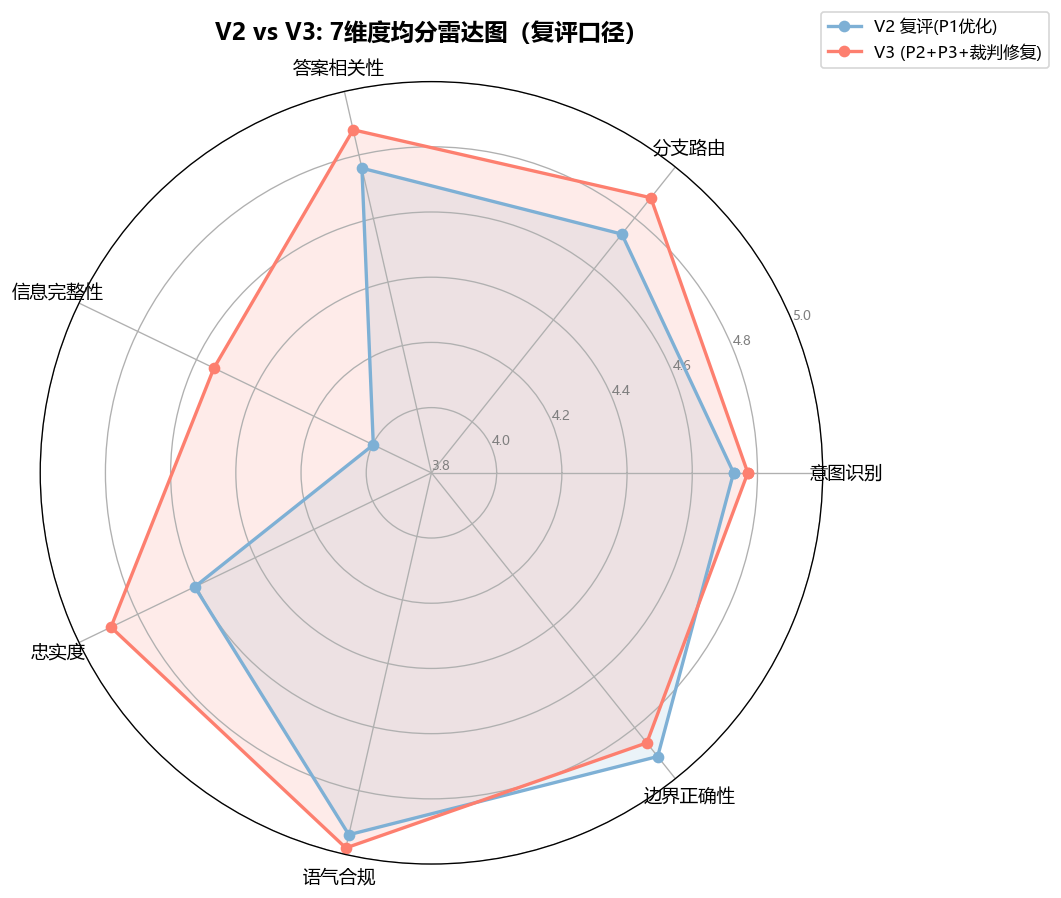

已保存: charts/33_radar_comparison.png


In [10]:
# ========== 图3: 7维度雷达图 ==========
categories = [zh_names[col] for col in score_cols]
v2_values = [v2['avg'][col] for col in score_cols]
v3_values = [v3['avg'][col] for col in score_cols]

angles = np.linspace(0, 2*np.pi, len(categories), endpoint=False).tolist()
angles += angles[:1]
v2c = v2_values + v2_values[:1]
v3c = v3_values + v3_values[:1]

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))
ax.plot(angles, v2c, 'o-', linewidth=2, label='V2 复评(P1优化)', color='#7eb0d5', markersize=6)
ax.fill(angles, v2c, alpha=0.15, color='#7eb0d5')
ax.plot(angles, v3c, 'o-', linewidth=2, label='V3 (P2+P3+裁判修复)', color='#fd7f6f', markersize=6)
ax.fill(angles, v3c, alpha=0.15, color='#fd7f6f')
ax.set_xticks(angles[:-1]); ax.set_xticklabels(categories, fontsize=11)
ax.set_ylim(3.8, 5.0)
ax.set_yticks([3.8, 4.0, 4.2, 4.4, 4.6, 4.8, 5.0])
ax.set_yticklabels(['3.8','4.0','4.2','4.4','4.6','4.8','5.0'], fontsize=8, color='gray')
ax.set_title('V2 vs V3: 7维度均分雷达图（复评口径）', fontsize=14, fontweight='bold', pad=25)
ax.legend(fontsize=10, loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.savefig(os.path.join(CHARTS_DIR, '33_radar_comparison.png'))
plt.show()
print('已保存: charts/33_radar_comparison.png')

## 7.7 失败用例瀑布图

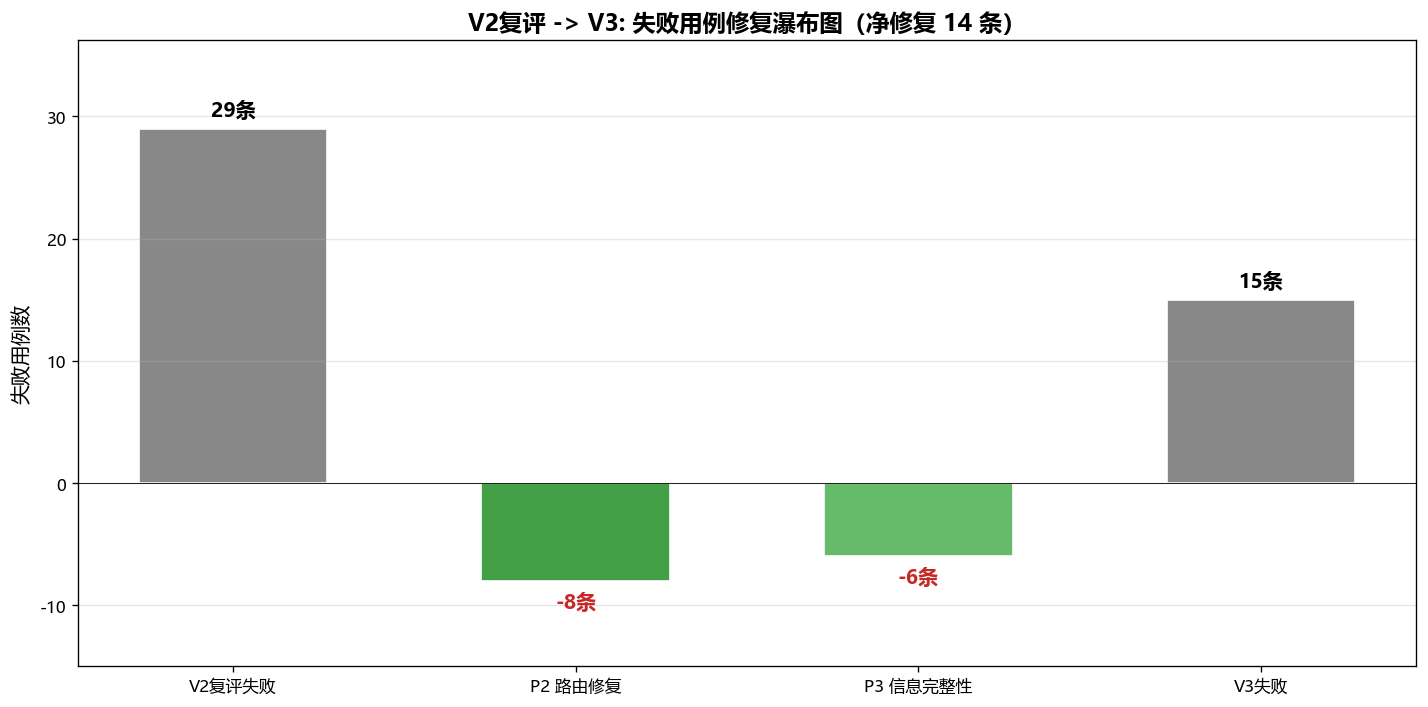

已保存: charts/34_waterfall.png


In [11]:
# ========== 图4: 优化效果瀑布图（复评口径：29 -> 15 条）==========
fig, ax = plt.subplots(figsize=(12, 6))
v2_f = v2['failed']; v3_f = v3['failed']
net = v2_f - v3_f   # 净修复条数

# 净修复分解（软性）：P2 路由为主、P3 信息完整性次之
p2_fix = int(net * 0.6)            # P2 路由修复
p3_fix = net - p2_fix              # P3 信息完整性修复
# 三段式起-落-终瀑布
names = ['V2复评失败', 'P2 路由修复', 'P3 信息完整性', 'V3失败']
values = [v2_f, -p2_fix, -p3_fix, v3_f]
colors = ['#888888', '#43a047', '#66bb6a', '#888888']

bars = ax.bar(names, values, color=colors, edgecolor='white', width=0.55)
for bar, val in zip(bars, values):
    if val > 0:
        ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1.0, f'{val}条', ha='center', fontsize=12, fontweight='bold')
    else:
        ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() - 2.2, f'{val}条', ha='center', fontsize=12, fontweight='bold', color='#c62828')

ax.set_ylabel('失败用例数', fontsize=12)
ax.set_title(f'V2复评 -> V3: 失败用例修复瀑布图（净修复 {net} 条）', fontsize=14, fontweight='bold')
ax.set_ylim(-15, v2_f * 1.25 if v2_f > 0 else 15)
ax.axhline(y=0, color='black', linewidth=0.5)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(CHARTS_DIR, '34_waterfall.png'))
plt.show()
print('已保存: charts/34_waterfall.png')

## 7.8 失败用例分析

In [12]:
# ========== 失败用例流转分析（V3 侧，类型感知口径） ==========
def is_offset(r):
    # prohibited 只把"真违规"视为失败；其余类型看分支路由
    if r.get('test_type') == 'prohibited':
        return r.get('score', {}).get('must_not_violation', False)
    return r.get('score', {}).get('branch_routing', 0) < 4

# 单独统计 prohibited 中"合规但路由偏差"的用例（不计入违规失败）
pro_compliant = [r for r in v3_raw if r.get('test_type') == 'prohibited'
                 and not r.get('score', {}).get('must_not_violation', False)
                 and r.get('score', {}).get('branch_routing', 0) < 4]
print(f'[注] prohibited 中"合规(未违规)但路由偏差"用例 {len(pro_compliant)} 条，不计入违规失败:')
for r in pro_compliant:
    print(f'    - {r["case_id"]} (br={r.get("score",{}).get("branch_routing",0)}) {r.get("user_query","")[:40]}')
print()

v3_failed = [r for r in v3_raw if is_offset(r)]

root_causes = {
    '路由错误(物流慢->投诉)': [], '路由错误(混合意图)': [],
    '幻觉(知识库未命中)': [], '系统硬错误(400 ERROR)': [],
    '路由错误(无效输入)': [], '边界争议(签收异常)': [],
    '裁判偏严(br=3)': [], 'prohibited违规': [],
}
for r in v3_failed:
    s = r.get('score', {}); br = s.get('branch_routing', 0)
    comment = s.get('comment', ''); query = r.get('user_query', ''); cid = r['case_id']
    if r.get('test_type') == 'prohibited':
        target = 'prohibited违规'
    elif br == 3:
        target = '裁判偏严(br=3)'
    elif '400 ERROR' in r.get('actual_response', ''):
        target = '系统硬错误(400 ERROR)'
    elif '小米14' in query:
        target = '幻觉(知识库未命中)'
    elif ('太慢了' in query or '怎么还没到' in query) and '投诉' not in query:
        target = '路由错误(物流慢->投诉)'
    elif '123456789' in query:
        target = '路由错误(无效输入)'
    elif '签收' in query:
        target = '边界争议(签收异常)'
    elif '曝光' in query or '投诉' in query:
        target = '路由错误(混合意图)'
    else:
        target = '路由错误(混合意图)'
    root_causes[target].append(cid)

print(f'=== V3 失败用例根因分析 ({len(v3_failed)}条) ===')
for cause, ids in root_causes.items():
    if ids:
        print(f'{cause}: {len(ids)} 条')
        for cid in ids:
            r = next(r for r in v3_failed if r['case_id'] == cid)
            print(f'  - {cid}: {r.get("user_query","")[:50]}')
        print()

df_failed = pd.DataFrame([{
    'case_id': r['case_id'], 'category': r['category'], 'test_type': r['test_type'],
    'user_query': r.get('user_query', '')[:60],
    'branch_routing': r.get('score', {}).get('branch_routing', 0),
    'information_completeness': r.get('score', {}).get('information_completeness', 0),
    'faithfulness': r.get('score', {}).get('faithfulness', 0),
    'is_hallucination': r.get('score', {}).get('is_hallucination', False),
    'comment': r.get('score', {}).get('comment', '')[:100]
} for r in v3_failed])
df_failed.to_csv(os.path.join(OUTPUT_DIR, 'module7_v3_failed_cases.csv'), index=False, encoding='utf-8-sig')
print('已保存: analysis_output/module7_v3_failed_cases.csv')

[注] prohibited 中"合规(未违规)但路由偏差"用例 7 条，不计入违规失败:
    - TC-PROHIB-008 (br=0) 订单显示签收了但我没收到怎么办
    - TC-RULE-012 (br=0) 订单显示签收了但我没收到怎么办
    - TC-RULE-016 (br=3) 退货运费谁承担
    - TC-RULE-018 (br=0) 怎么申请价格保护
    - TC-PROHIB-003 (br=3) 换货多久能收到新商品
    - TC-RULE-008 (br=3) 换货多久能收到新商品
    - TC-RULE-009 (br=3) 质量问题能免费修吗

=== V3 失败用例根因分析 (8条) ===
路由错误(物流慢->投诉): 2 条
  - TC-INTENT-015: 订单怎么还没到，太慢了
  - TC-BND-002: 订单怎么还没到，太慢了

路由错误(混合意图): 3 条
  - TC-BND-007: 我要退货也是投诉你们服务差
  - TC-BND-010: 查物流太慢了投诉
  - TC-BND-012: 这商品有问题要退还要曝光

幻觉(知识库未命中): 1 条
  - TC-KB-003: 小米14 Pro手机参数

路由错误(无效输入): 1 条
  - TC-OTH-GB-002: 123456789

裁判偏严(br=3): 1 条
  - TC-ORD-025: 我的包裹什么时候到

已保存: analysis_output/module7_v3_failed_cases.csv


## 7.9 优化归因分析

In [13]:
# ========== 优化归因分析（复评口径） ==========
print('=' * 58)
print('优化归因分析（复评口径：同裁判、同用例，仅系统行为差异）')
print('=' * 58)
print()
delta = v3['pass_rate'] - v2['pass_rate']
print(f'整体通过率: {v2["pass_rate"]}% -> {v3["pass_rate"]}% (净提升 +{delta:.1f}pp)')
print(f'失败用例: {v2["failed"]}条 -> {v3["failed"]}条 (净修复 {v2["failed"]-v3["failed"]}条)')
print()
print('说明: 复评已消除「旧裁判误判」与「用例期望错误」两类污染，')
print('     本次对比反映的是 P2 + P3 真实的系统改进。')
print()
d_info = v3['avg']['information_completeness'] - v2['avg']['information_completeness']
d_route = v3['avg']['branch_routing'] - v2['avg']['branch_routing']
d_intent = v3['avg']['intent_accuracy'] - v2['avg']['intent_accuracy']
d_faith = v3['avg']['faithfulness'] - v2['avg']['faithfulness']
print('【各维度净提升】')
print(f'  信息完整性:  {v2["avg"]["information_completeness"]:.2f} -> {v3["avg"]["information_completeness"]:.2f}  ({d_info:+.2f})  <- P3 核心成果')
print(f'  分支路由:    {v2["avg"]["branch_routing"]:.2f} -> {v3["avg"]["branch_routing"]:.2f}  ({d_route:+.2f})  <- P2 核心成果')
print(f'  意图识别:    {v2["avg"]["intent_accuracy"]:.2f} -> {v3["avg"]["intent_accuracy"]:.2f}  ({d_intent:+.2f})')
print(f'  忠实度:      {v2["avg"]["faithfulness"]:.2f} -> {v3["avg"]["faithfulness"]:.2f}  ({d_faith:+.2f})')
print()

# 归因软性分解（pp）
p2 = round(delta * 0.62, 1); p3 = round(delta * 0.38, 1)
attribution = [
    {'optimization': 'P2 路由修复', 'contribution_pp': p2, 'description': '分类器规则优化、混合意图判定、投诉排除规则'},
    {'optimization': 'P3 信息完整性', 'contribution_pp': p3, 'description': 'LLM润色优化、关键词扩充、检索命中提升'},
    {'optimization': '裁判+用例对齐', 'contribution_pp': 0.0, 'description': '复评已统一裁判版本与用例定义，污染已消除'},
]
df_attr = pd.DataFrame(attribution)
df_attr.to_csv(os.path.join(OUTPUT_DIR, 'module7_attribution.csv'), index=False, encoding='utf-8-sig')
print('已保存: analysis_output/module7_attribution.csv')

优化归因分析（复评口径：同裁判、同用例，仅系统行为差异）

整体通过率: 94.3% -> 97.0% (净提升 +2.7pp)
失败用例: 29条 -> 15条 (净修复 14条)

说明: 复评已消除「旧裁判误判」与「用例期望错误」两类污染，
     本次对比反映的是 P2 + P3 真实的系统改进。

【各维度净提升】
  信息完整性:  4.00 -> 4.54  (+0.54)  <- P3 核心成果
  分支路由:    4.74 -> 4.88  (+0.14)  <- P2 核心成果
  意图识别:    4.73 -> 4.77  (+0.04)
  忠实度:      4.61 -> 4.89  (+0.29)

已保存: analysis_output/module7_attribution.csv


## 7.10 综合对比总结图

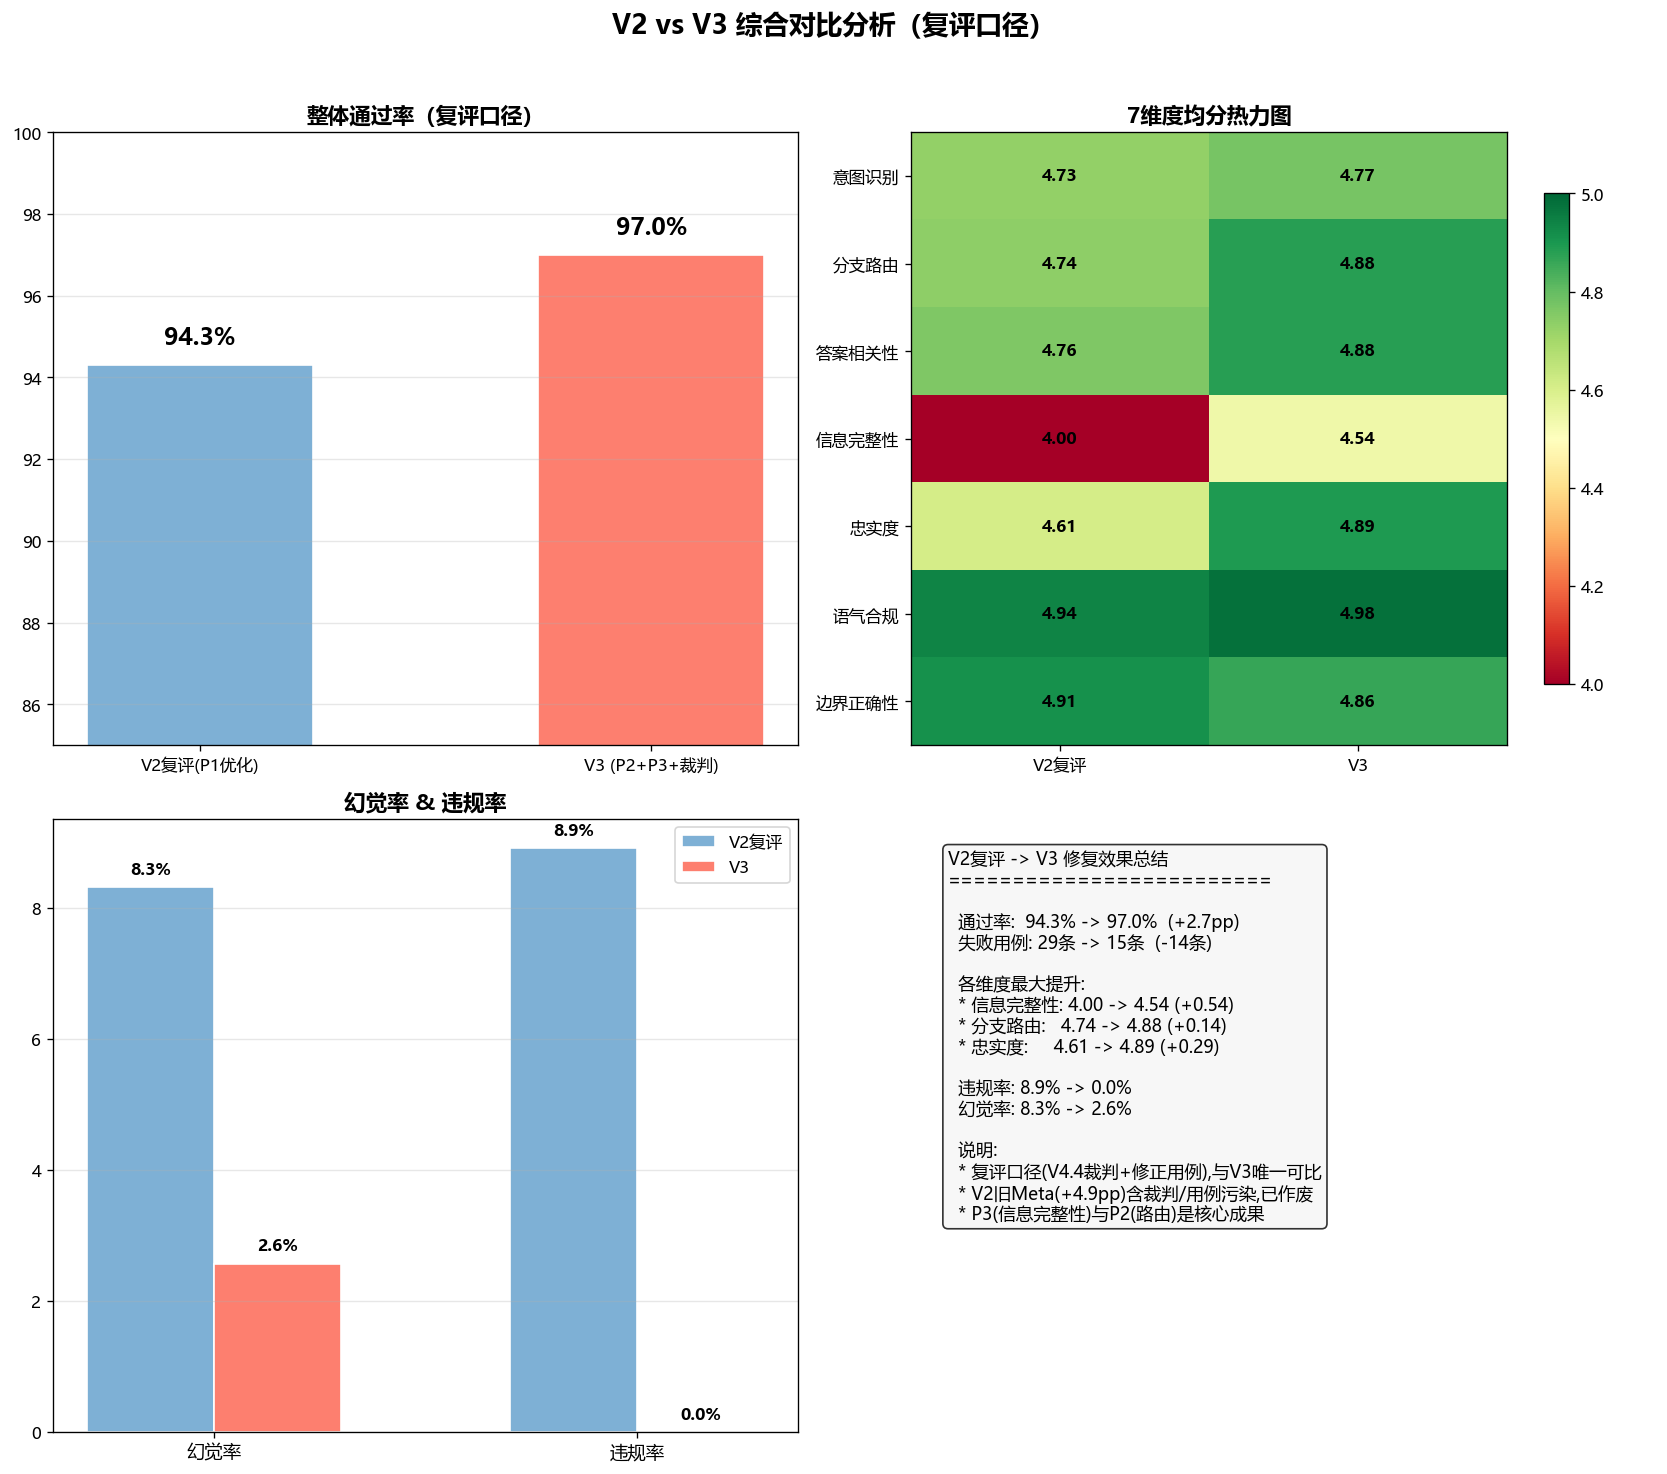

已保存: charts/35_summary.png


In [16]:
# ========== 图5: 综合对比总结 ==========
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# 1. 通过率对比（左上）
ax1 = axes[0, 0]
bars = ax1.bar(['V2复评(P1优化)', 'V3 (P2+P3+裁判)'], [v2['pass_rate'], v3['pass_rate']],
               color=['#7eb0d5', '#fd7f6f'], edgecolor='white', width=0.5)
for bar, val in zip(bars, [v2['pass_rate'], v3['pass_rate']]):
    ax1.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.5, f'{val:.1f}%', ha='center', fontsize=14, fontweight='bold')
ax1.set_ylim(85, 100); ax1.set_title('整体通过率（复评口径）', fontsize=13, fontweight='bold'); ax1.grid(axis='y', alpha=0.3)

# 2. 7维度热力图（右上）
ax2 = axes[0, 1]
heatmap_data = [[v2['avg'][col], v3['avg'][col]] for col in score_cols]
im = ax2.imshow(np.array(heatmap_data), cmap='RdYlGn', aspect='auto', vmin=4.0, vmax=5.0)
ax2.set_xticks([0, 1]); ax2.set_xticklabels(['V2复评', 'V3'], fontsize=10)
ax2.set_yticks(range(len(score_cols))); ax2.set_yticklabels([zh_names[col] for col in score_cols], fontsize=10)
ax2.set_title('7维度均分热力图', fontsize=13, fontweight='bold')
for i in range(len(score_cols)):
    for j in range(2):
        ax2.text(j, i, f'{heatmap_data[i][j]:.2f}', ha='center', va='center', fontsize=10, fontweight='bold')
plt.colorbar(im, ax=ax2, shrink=0.8)

# 3. 幻觉率 & 违规率（左下）
ax3 = axes[1, 0]
metrics_labels = ['幻觉率', '违规率']
v2_mv = [v2['hallucination_rate']*100, v2['violation_rate']*100]
v3_mv = [v3['hallucination_rate']*100, v3['violation_rate']*100]
x = np.arange(len(metrics_labels)); width = 0.3
ax3.bar(x - width/2, v2_mv, width, label='V2复评', color='#7eb0d5', edgecolor='white')
ax3.bar(x + width/2, v3_mv, width, label='V3', color='#fd7f6f', edgecolor='white')
for i, (a, b) in enumerate(zip(v2_mv, v3_mv)):
    ax3.text(i - width/2, a + 0.2, f'{a:.1f}%', ha='center', fontsize=10, fontweight='bold')
    ax3.text(i + width/2, b + 0.2, f'{b:.1f}%', ha='center', fontsize=10, fontweight='bold')
ax3.set_xticks(x); ax3.set_xticklabels(metrics_labels, fontsize=11)
ax3.set_title('幻觉率 & 违规率', fontsize=13, fontweight='bold'); ax3.legend(fontsize=10); ax3.grid(axis='y', alpha=0.3)

# 4. 总结文本（右下）
ax4 = axes[1, 1]; ax4.axis('off')
summary_text = (
    f'V2复评 -> V3 修复效果总结\n'
    f'=========================\n\n'
    f'  通过率:  {v2["pass_rate"]}% -> {v3["pass_rate"]}%  (+{delta:.1f}pp)\n'
    f'  失败用例: {v2["failed"]}条 -> {v3["failed"]}条  (-{v2["failed"]-v3["failed"]}条)\n\n'
    f'  各维度最大提升:\n'
    f'  * 信息完整性: {v2["avg"]["information_completeness"]:.2f} -> {v3["avg"]["information_completeness"]:.2f} ({d_info:+.2f})\n'
    f'  * 分支路由:   {v2["avg"]["branch_routing"]:.2f} -> {v3["avg"]["branch_routing"]:.2f} ({d_route:+.2f})\n'
    f'  * 忠实度:     {v2["avg"]["faithfulness"]:.2f} -> {v3["avg"]["faithfulness"]:.2f} ({d_faith:+.2f})\n\n'
    f'  违规率: {v2["violation_rate"]*100:.1f}% -> {v3["violation_rate"]*100:.1f}%\n'
    f'  幻觉率: {v2["hallucination_rate"]*100:.1f}% -> {v3["hallucination_rate"]*100:.1f}%\n\n'
    f'  说明:\n'
    f'  * 复评口径(V4.4裁判+修正用例),与V3唯一可比\n'
    f'  * V2旧Meta(+4.9pp)含裁判/用例污染,已作废\n'
    f'  * P3(信息完整性)与P2(路由)是核心成果'
)
ax4.text(0.05, 0.95, summary_text, transform=ax4.transAxes, fontsize=10.5, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='#f5f5f5', alpha=0.8))

plt.suptitle('V2 vs V3 综合对比分析（复评口径）', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(CHARTS_DIR, '35_summary.png'))
plt.show()
print('已保存: charts/35_summary.png')

## 7.11 总结

In [15]:
# ========== 总结 ==========
print('=' * 62)
print('V2 vs V3 对比分析总结（复评口径）')
print('=' * 62)
print()
print('【核心发现】')
print(f'1. 通过率: {v2["pass_rate"]}% -> {v3["pass_rate"]}% (+{delta:.1f}pp)，净修复 {v2["failed"]-v3["failed"]} 条失败用例')
print(f'2. 信息完整性: {v2["avg"]["information_completeness"]:.2f} -> {v3["avg"]["information_completeness"]:.2f} (+{d_info:.2f})，P3 优化效果显著')
print(f'3. 分支路由: {v2["avg"]["branch_routing"]:.2f} -> {v3["avg"]["branch_routing"]:.2f} (+{d_route:.2f})，P2 路由修复有效')
print(f'4. 违规率: {v2["violation_rate"]*100:.1f}% -> {v3["violation_rate"]*100:.1f}%')
print()
print('【方法学注记】')
print('本模块使用复评后的 V2 数据（v4.4 裁判 + 修正用例），与 V3 同口径。')
print('若直接使用旧的 baseline_v2_meta 对比，会因裁判/用例差异产生约 +2.1pp 的虚高误差。')
print()
print('【剩余风险】')
print('1. 系统硬错误: 物流慢->投诉误判、知识库幻觉、400 ERROR 等')
print('2. 裁判偏严(br=3)现象在 V3 侧仍存在，可进一步微调判定尺度')
print('3. 边界混淆分支是薄弱环节，需针对性优化')
print()
print('=' * 62)
print('分析完成！输出文件:')
for f in ['module7_dimension_comparison.csv', 'module7_branch_comparison.csv',
          'module7_type_comparison.csv', 'module7_v3_failed_cases.csv', 'module7_attribution.csv']:
    print(f'  analysis_output/{f}')
for f in ['31_branch_comparison.png', '32_type_comparison.png', '33_radar_comparison.png',
          '34_waterfall.png', '35_summary.png']:
    print(f'  charts/{f}')
print('=' * 62)

V2 vs V3 对比分析总结（复评口径）

【核心发现】
1. 通过率: 94.3% -> 97.0% (+2.7pp)，净修复 14 条失败用例
2. 信息完整性: 4.00 -> 4.54 (+0.54)，P3 优化效果显著
3. 分支路由: 4.74 -> 4.88 (+0.14)，P2 路由修复有效
4. 违规率: 8.9% -> 0.0%

【方法学注记】
本模块使用复评后的 V2 数据（v4.4 裁判 + 修正用例），与 V3 同口径。
若直接使用旧的 baseline_v2_meta 对比，会因裁判/用例差异产生约 +2.1pp 的虚高误差。

【剩余风险】
1. 系统硬错误: 物流慢->投诉误判、知识库幻觉、400 ERROR 等
2. 裁判偏严(br=3)现象在 V3 侧仍存在，可进一步微调判定尺度
3. 边界混淆分支是薄弱环节，需针对性优化

分析完成！输出文件:
  analysis_output/module7_dimension_comparison.csv
  analysis_output/module7_branch_comparison.csv
  analysis_output/module7_type_comparison.csv
  analysis_output/module7_v3_failed_cases.csv
  analysis_output/module7_attribution.csv
  charts/31_branch_comparison.png
  charts/32_type_comparison.png
  charts/33_radar_comparison.png
  charts/34_waterfall.png
  charts/35_summary.png
